
TRAINING ENSEMBLE
Training Finished.
T=0.0°C | ALARM | fr_std=5029.66 kHz | Sensitivity=[0.02809183 0.02334834 0.91548526 0.03307457]
T=5.3°C | WARNING | fr_std=3379.58 kHz | Sensitivity=[0.03847768 0.03765641 0.87740806 0.04645784]
T=10.5°C | SAFE | fr_std=134.55 kHz | Sensitivity=[0.02850498 0.03100057 0.89518259 0.04531186]
T=15.8°C | SAFE | fr_std=0.00 kHz | Sensitivity=[0.02418592 0.02024503 0.91605284 0.03951621]
T=21.1°C | WARNING | fr_std=1152.06 kHz | Sensitivity=[0.0176891  0.018118   0.93118038 0.03301252]
T=26.3°C | ALARM | fr_std=5915.39 kHz | Sensitivity=[0.01388591 0.01482183 0.93761253 0.03367973]
T=31.6°C | WARNING | fr_std=3192.42 kHz | Sensitivity=[0.01355111 0.01203908 0.93917329 0.03523652]
T=36.8°C | SAFE | fr_std=0.00 kHz | Sensitivity=[0.01097114 0.00977865 0.9427604  0.03648981]
T=42.1°C | SAFE | fr_std=0.00 kHz | Sensitivity=[0.0099312  0.01304377 0.93836983 0.0386552 ]
T=47.4°C | SAFE | fr_std=0.00 kHz | Sensitivity=[0.02046873 0.01727845 0.92180449 0.040448

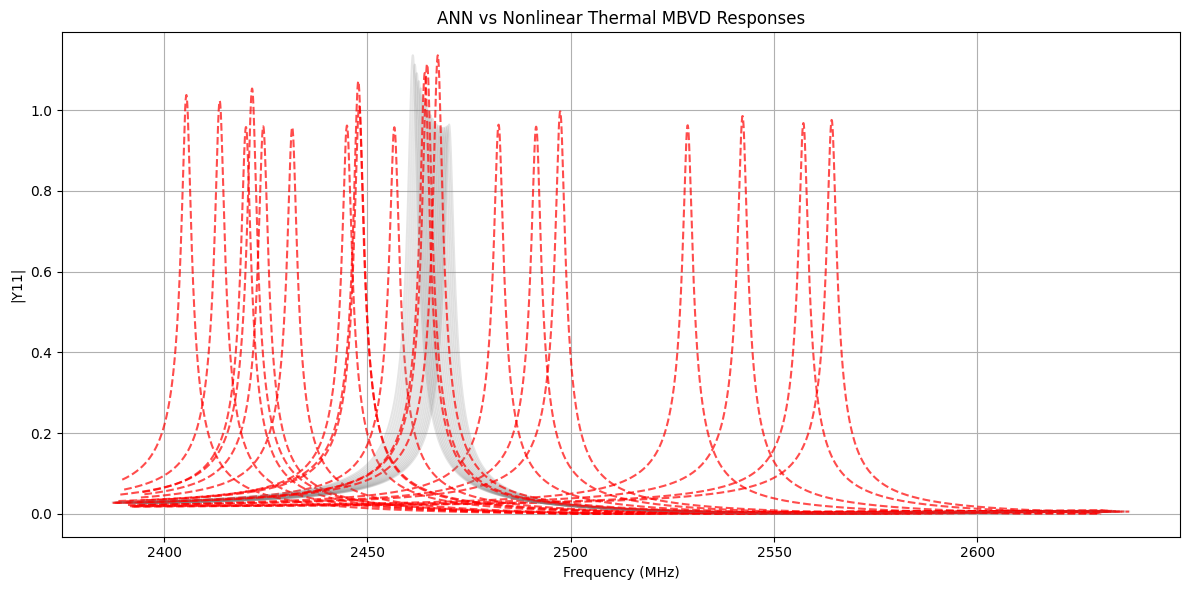

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ====================================================
# REPRODUCIBILITY
# ====================================================

SEED = 0

np.random.seed(SEED)

tf.random.set_seed(SEED)

# ====================================================
# FIXED MBVD PARAMETERS
# ====================================================

C0 = 7.95e-13

R0 = 0.25

# ====================================================
# REFERENCE PARAMETERS
# ====================================================

fr0 = 2.468e9

Qs0 = 887

Qp0 = 3770

k20 = 0.08

# ====================================================
# THERMAL COEFFICIENTS
# ====================================================

TCF1 = -35e-6
TCF2 = -4e-8
TCF3 = 2e-10

alpha1 = 5e-4
alpha2 = 2e-5

beta1 = 0.02
beta2 = 1e-4

gamma1 = 0.015
gamma2 = 8e-5

# ====================================================
# SETTINGS
# ====================================================

N_ENSEMBLE = 5

N_MC = 500

EPOCHS = 1000

BATCH_SIZE = 16

PI = np.pi

# ====================================================
# FULL NONLINEAR THERMAL MBVD
# ====================================================

def mbvd_ecp(T):

    dT = T - 25

    # ------------------------------------------------
    # fr(T)
    # ------------------------------------------------

    fr = fr0 * (
        1
        + TCF1*dT
        + TCF2*dT**2
        + TCF3*dT**3
    )

    # ------------------------------------------------
    # k2(T)
    # ------------------------------------------------

    k2 = k20 * (
        1
        + alpha1*dT
        + alpha2*dT**2
    )

    # ------------------------------------------------
    # Qs(T)
    # ------------------------------------------------

    Qs = Qs0 * np.exp(
        -beta1*dT/100
        + beta2*dT**2/10000
    )

    # ------------------------------------------------
    # Qp(T)
    # ------------------------------------------------

    Qp = Qp0 * np.exp(
        -gamma1*dT/100
        + gamma2*dT**2/10000
    )

    # ------------------------------------------------
    # fa(T)
    # ------------------------------------------------

    inside = 1 - (16*k2)/(PI**2)

    inside = np.maximum(inside,1e-12)

    fa = (
        2*fr
        /
        (
            1
            +
            np.sqrt(inside)
        )
    )

    wr = 2*np.pi*fr

    wa = 2*np.pi*fa

    # ------------------------------------------------
    # MBVD PARAMETERS
    # ------------------------------------------------

    Cm = C0 * (
        (fa/fr)**2 - 1
    )

    Cm = np.maximum(Cm,1e-18)

    Lm = 1 / (
        (wr**2) * Cm
    )

    Lm = np.maximum(Lm,1e-18)

    # ------------------------------------------------
    # Rm
    # ------------------------------------------------

    Rm = (

        wr * (Lm/Qs)

    ) - R0

    # ------------------------------------------------
    # Rs
    # ------------------------------------------------

    Rs = (

        wa * (Lm/Qp)

    ) - Rm

    # ------------------------------------------------
    # SAFETY
    # ------------------------------------------------

    Rm = np.maximum(Rm,1e-12)

    Rs = np.maximum(Rs,1e-12)

    return np.array([

        Rm,
        Lm,
        Cm,
        Rs

    ],dtype=np.float32)

# ====================================================
# MBVD ADMITTANCE
# ====================================================

def simulate_Y11(Rm,Lm,Cm,Rs,T,freq_points=4000):

    dT = T - 25

    # ------------------------------------------------
    # fr(T)
    # ------------------------------------------------

    fr = fr0 * (
        1
        + TCF1*dT
        + TCF2*dT**2
        + TCF3*dT**3
    )

    # ------------------------------------------------
    # k2(T)
    # ------------------------------------------------

    k2 = k20 * (
        1
        + alpha1*dT
        + alpha2*dT**2
    )

    inside = 1 - (16*k2)/(PI**2)

    inside = np.maximum(inside,1e-12)

    # ------------------------------------------------
    # fa(T)
    # ------------------------------------------------

    fa = (
        2*fr
        /
        (
            1
            +
            np.sqrt(inside)
        )
    )

    # ------------------------------------------------
    # FREQUENCY GRID
    # ------------------------------------------------

    freqs = np.linspace(
        fr*0.97,
        fa*1.03,
        freq_points
    )

    w = 2*np.pi*freqs

    # ------------------------------------------------
    # SAFETY
    # ------------------------------------------------

    Cm = np.maximum(Cm,1e-18)

    Lm = np.maximum(Lm,1e-18)

    Rm = np.maximum(Rm,1e-12)

    Rs = np.maximum(Rs,1e-12)

    # ------------------------------------------------
    # STATIC BRANCH
    # ------------------------------------------------

    Zs = (
        R0
        +
        1/(1j*w*C0)
    )

    # ------------------------------------------------
    # MOTIONAL BRANCH
    # ------------------------------------------------

    Zm = (
        Rm
        +
        1j*w*Lm
        +
        1/(1j*w*Cm)
    )

    # ------------------------------------------------
    # PARALLEL NETWORK
    # ------------------------------------------------

    Zp = 1/(1/Zs + 1/Zm)

    # ------------------------------------------------
    # TOTAL IMPEDANCE
    # ------------------------------------------------

    Ztotal = Rs + Zp

    # ------------------------------------------------
    # ADMITTANCE
    # ------------------------------------------------

    Y11 = np.abs(1/Ztotal)

    Y11 = np.nan_to_num(
        Y11,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    return freqs, Y11

# ====================================================
# TRAINING DATA
# ====================================================

train_temps = np.array(
    [0,25,60,85,100],
    dtype=np.float32
)

X_train = train_temps.reshape(-1,1)

Y_train = np.array([
    mbvd_ecp(T)
    for T in train_temps
])

# ====================================================
# NORMALIZATION
# ====================================================

X_mean = X_train.mean()

X_std = np.maximum(
    X_train.std(),
    1e-12
)

ECP_mean = Y_train.mean(axis=0)

ECP_std = np.maximum(
    Y_train.std(axis=0),
    1e-12
)

Xn = (X_train - X_mean)/X_std

Yn = (Y_train - ECP_mean)/ECP_std

# ====================================================
# BUILD MODEL
# ====================================================

def build_model():

    model = tf.keras.Sequential([

        tf.keras.layers.Input(shape=(1,)),

        tf.keras.layers.Dense(
            64,
            activation='tanh'
        ),

        tf.keras.layers.Dense(
            64,
            activation='tanh'
        ),

        tf.keras.layers.Dense(
            32,
            activation='tanh'
        ),

        tf.keras.layers.Dense(4)

    ])

    model.compile(

        optimizer=tf.keras.optimizers.Adam(1e-3),

        loss='mse'

    )

    return model

# ====================================================
# TRAIN ENSEMBLE
# ====================================================

ensemble = []

print("\n====================================")
print("TRAINING ENSEMBLE")
print("====================================")

for i in range(N_ENSEMBLE):

    tf.keras.backend.clear_session()

    tf.random.set_seed(i+1)

    np.random.seed(i+1)

    model = build_model()

    earlystop = tf.keras.callbacks.EarlyStopping(

        monitor='loss',

        patience=50,

        restore_best_weights=True

    )

    model.fit(

        Xn,
        Yn,

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        verbose=0,

        callbacks=[earlystop]

    )

    ensemble.append(model)

print("Training Finished.")

# ====================================================
# ENSEMBLE PREDICTION
# ====================================================

def ensemble_predict(T):

    Tn = (
        np.array([[T]],dtype=np.float32)
        - X_mean
    ) / X_std

    preds = []

    for model in ensemble:

        yp = model.predict(
            Tn,
            verbose=0
        )[0]

        yp = yp*ECP_std + ECP_mean

        preds.append(yp)

    return np.array(preds)

# ====================================================
# ALARM THRESHOLDS
# ====================================================

FR_SAFE_MAX = 1e6

FR_WARNING_MAX = 5e6

# ====================================================
# TEMPERATURE RANGE
# ====================================================

temps_sweep = np.linspace(0,100,20)

alarm_status = []

# ====================================================
# MAIN LOOP
# ====================================================

for T in temps_sweep:

    preds = ensemble_predict(T)

    mean_params = preds.mean(axis=0)

    epi_std = preds.std(axis=0)

    # ------------------------------------------------
    # ALEATORIC UNCERTAINTY
    # ------------------------------------------------

    alea_samples = []

    for _ in range(50):

        noisy = mbvd_ecp(T).copy()

        noise = np.random.normal(
            0,
            0.001,
            size=4
        )

        noisy = noisy * (1 + noise)

        noisy = np.maximum(noisy,1e-18)

        alea_samples.append(noisy)

    alea_samples = np.array(alea_samples)

    alea_std = alea_samples.std(axis=0)

    # ------------------------------------------------
    # COMBINED UNCERTAINTY
    # ------------------------------------------------

    combined_std = np.sqrt(

        epi_std**2

        +

        alea_std**2

    )

    combined_std = np.maximum(
        combined_std,
        1e-18
    )

    # =================================================
    # MONTE CARLO PROPAGATION
    # =================================================

    Y_mc = []

    fr_mc = []

    for _ in range(N_MC):

        relative_std = (

            combined_std

            /

            np.maximum(
                np.abs(mean_params),
                1e-18
            )

        )

        # --------------------------------------------
        # LIMIT EXTREME PERTURBATIONS
        # --------------------------------------------

        relative_std = np.minimum(
            relative_std,
            0.01
        )

        # --------------------------------------------
        # LOG-SPACE SAMPLING
        # --------------------------------------------

        log_mean = np.log(
            np.maximum(mean_params,1e-18)
        )

        sample = np.exp(

            np.random.normal(
                log_mean,
                relative_std
            )

        )

        # --------------------------------------------
        # MBVD RESPONSE
        # --------------------------------------------

        f,Y = simulate_Y11(
            *sample,
            T
        )

        Y_mc.append(Y)

        # --------------------------------------------
        # LOCAL RESONANCE SEARCH
        # --------------------------------------------

        search_window = np.abs(
            f - fr0
        ) < 10e6

        local_f = f[search_window]

        local_Y = Y[search_window]

        fr_local = local_f[
            np.argmax(local_Y)
        ]

        fr_mc.append(fr_local)

    Y_mc = np.array(Y_mc)

    fr_mc = np.array(fr_mc)

    # =================================================
    # RESPONSE STATISTICS
    # =================================================

    fr_std = np.std(fr_mc)

    # =================================================
    # ALARM LOGIC
    # =================================================

    if fr_std < FR_SAFE_MAX:

        status = 'SAFE'

    elif fr_std < FR_WARNING_MAX:

        status = 'WARNING'

    else:

        status = 'ALARM'

    # =================================================
    # RELATIVE ECP SENSITIVITY
    # =================================================

    relative_unc = (

        combined_std

        /

        np.maximum(
            np.abs(mean_params),
            1e-18
        )

    )

    total_unc = np.sum(relative_unc)

    if total_unc < 1e-18:

        ecp_contrib = np.zeros(4)

    else:

        ecp_contrib = relative_unc / total_unc

    # =================================================
    # STORE RESULTS
    # =================================================

    alarm_status.append(

        (
            T,
            status,
            fr_std,
            ecp_contrib
        )

    )

    # =================================================
    # PRINT RESULTS
    # =================================================

    print(
        f"T={T:.1f}°C | "
        f"{status} | "
        f"fr_std={fr_std/1e3:.2f} kHz | "
        f"Sensitivity={ecp_contrib}"
    )

# ====================================================
# VISUALIZATION
# ====================================================

plt.figure(figsize=(12,6))

for T in temps_sweep:

    f,Y_true = simulate_Y11(
        *mbvd_ecp(T),
        T
    )

    plt.plot(
        f/1e6,
        Y_true,
        color='gray',
        alpha=0.2
    )

    preds = ensemble_predict(T)

    mean_params = preds.mean(axis=0)

    _,Y_pred = simulate_Y11(
        *mean_params,
        T
    )

    plt.plot(
        f/1e6,
        Y_pred,
        '--',
        color='red',
        alpha=0.7
    )

plt.xlabel("Frequency (MHz)")

plt.ylabel("|Y11|")

plt.title(
    "ANN vs Nonlinear Thermal MBVD Responses"
)

plt.grid(True)

plt.tight_layout()

plt.show()